# MPS loader batching benchmark

Compare fetching individual rows with `__getitem__` against fetching whole batches with `__getitems__`. Both use the same tensors and `dict_collate_fn`: the first path stacks rows, while the second returns the batch directly.

We time complete passes through the loader on MPS, excluding data preparation and model fitting.

In [9]:
from pathlib import Path
from time import perf_counter
import platform
import sys

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset

# Import this checkout from either the repository root or examples/.
ROOT = Path.cwd() if (Path.cwd() / "scdesigner/src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "scdesigner/src"))
from scdesigner.data.loader import adata_loader, dict_collate_fn

SEED = 42
N_CELLS, N_GENES = 10000, 2000
BATCH_SIZES = [128, 512, 1024, 2048]
REPEATS = 5
FORMULAS = {"mean": "~ group + covariate", "dispersion": "~ 1"}

print(f"Python {platform.python_version()} | PyTorch {torch.__version__}")
print(f"{platform.platform()} | Device: MPS")

Python 3.11.8 | PyTorch 2.6.0.dev20241112
macOS-26.5.2-arm64-arm-64bit | Device: MPS


In [10]:
rng = np.random.default_rng(SEED)
adata = ad.AnnData(
    X=rng.poisson(1.0, size=(N_CELLS, N_GENES)).astype(np.float32),
    obs=pd.DataFrame(
        {"group": pd.Categorical(rng.choice(["A", "B", "C"], N_CELLS)),
         "covariate": rng.normal(size=N_CELLS)},
        index=[f"cell_{i}" for i in range(N_CELLS)],
    ),
)
# Reuse the same row order in every pass; permutation generation is not timed.
ORDERS = {
    "sequential": list(range(N_CELLS)),
    "shuffled": np.random.default_rng(SEED).permutation(N_CELLS).tolist(),
}
print(f"Data: {adata.n_obs:,} cells × {adata.n_vars:,} genes (float32)")

Data: 10,000 cells × 2,000 genes (float32)


## Timing helpers

The wrapper exposes only `__getitem__`, reusing the original dataset's tensors. MPS synchronization makes the timer wait for GPU work to finish.

In [11]:
class RowDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):
        return self.dataset[index]


def time_pass(loader):
    torch.mps.synchronize()
    start = perf_counter()
    for _ in loader:
        pass
    torch.mps.synchronize()
    return perf_counter() - start

## Run the experiment

For each sampling order and batch size, benchmark one method at a time: warm up once, then time five passes. Both methods use the same row indices.

In [12]:
dataset = adata_loader(adata, FORMULAS, device="mps").dataset
methods = {"__getitem__": RowDataset(dataset), "__getitems__": dataset}
measurements = []

for order, indices in ORDERS.items():
    for batch_size in BATCH_SIZES:
        for method, data in methods.items():
            loader = DataLoader(
                data, batch_size=batch_size, sampler=indices, collate_fn=dict_collate_fn
            )
            time_pass(loader)  # Warm-up.

            for _ in range(REPEATS):
                seconds = time_pass(loader)
                measurements.append({
                    "order": order,
                    "batch_size": batch_size,
                    "method": method,
                    "seconds": seconds,
                })

timings = pd.DataFrame(measurements)

In [13]:
# Median seconds per complete pass, and the ratio of old to new time.
results = timings.pivot_table(
    index=["order", "batch_size"], columns="method", values="seconds", aggfunc="median"
)
results["speedup"] = results["__getitem__"] / results["__getitems__"]
results.round(4)

method                 __getitem__  __getitems__  speedup
order      batch_size                                    
sequential 128              0.1936        0.0473   4.0904
           512              0.2018        0.0275   7.3349
           1024             0.2085        0.0207  10.0753
           2048             0.2312        0.0187  12.3571
shuffled   128              0.1869        0.0398   4.6991
           512              0.2506        0.0323   7.7596
           1024             0.2054        0.0223   9.2106
           2048             0.2242        0.0174  12.8700

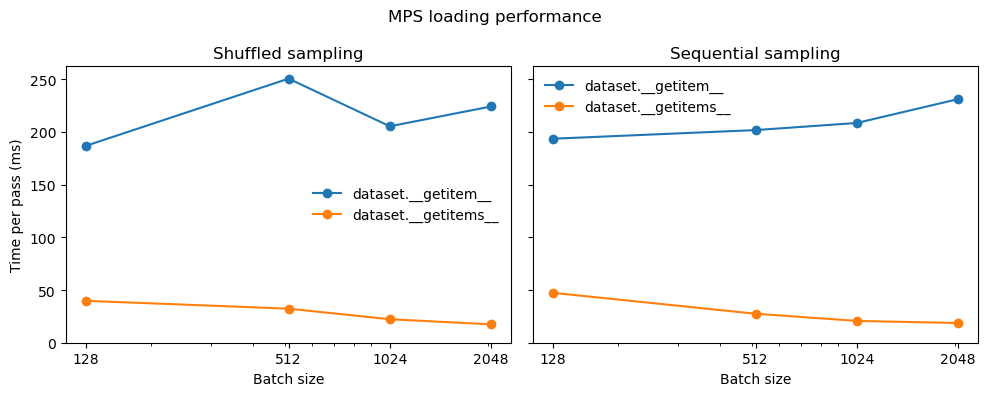

In [14]:
colors = {"__getitem__": "tab:blue", "__getitems__": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, order in zip(axes, ["shuffled", "sequential"]):
    values = results.loc[order]
    for method, color in colors.items():
        ax.plot(values.index, 1000 * values[method], marker="o", color=color, label=f"dataset.{method}")
    ax.set(xscale="log", title=f"{order.capitalize()} sampling", xlabel="Batch size", ylim=(0, None))
    ax.set_xticks(BATCH_SIZES, labels=BATCH_SIZES)
    ax.legend(frameon=False)
axes[0].set_ylabel("Time per pass (ms)")
fig.suptitle("MPS loading performance")
fig.tight_layout()
plt.show()